In [1]:
from utils.JetGraphProducer import JetGraphProducer
from utils.LundTreeUtilities import OnTheFlyNormalizer
import torch

# Produce the graphs. The call to JetGraphProducer will produce the graphs and
# save them in the specified directory if it is not already present.
qcd = JetGraphProducer(
        "test_data/qcd/",
        "QCD",
        n_store_jets=2,
        use_lund_decomp=True,
        n_lund_vars=5,
        save_energy_fractions=True,
        weights="xsec",
        verbose=True,
        label=0,
    )

s1 = JetGraphProducer(
        "test_data/rinv_0p3",
        "SVJ_3100_0p3",
        n_store_jets=2,
        use_lund_decomp=True,
        n_lund_vars=5,
        save_energy_fractions=True,
        weights="xsec",
        verbose=True,
        label=1,
    )

s2 = JetGraphProducer(
        "test_data/rinv_0p5",
        "SVJ_3100_0p5",
        n_store_jets=2,
        use_lund_decomp=True,
        n_lund_vars=5,
        save_energy_fractions=True,
        weights="xsec",
        verbose=True,
        label=1,
    )

# Compute the means and stds for the normalizer (if required)
means, stds = 0., 0.
weights = []

for graph in qcd:
    means += graph.x.sum(dim=0)*graph.w
    weights.append(graph.w)
means /= sum(weights)

for graph in qcd:
    stds += ((graph.x - means)**2).sum(dim=0)*graph.w

stds /= sum(weights)
stds = torch.sqrt(stds)

normalizer = OnTheFlyNormalizer(["x"], means, stds)

Processing...


Processing test_data\rinv_0p3/PFNanoSuper_sChannel_mZprime-3100GeV_mDark-20GeV_rInv-0p3_alpha-peak.root


  0%|          | 0/2861 [00:00<?, ?it/s]c:\Users\sgnas\SVJ_GNN\utils\JetGraphProducer.py:665: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  edge_index=torch.tensor(adjacency, dtype=torch.long),
100%|██████████| 2861/2861 [00:55<00:00, 51.45it/s]
Done!
Processing...


Processing test_data\rinv_0p5/PFNanoSuper_sChannel_mZprime-3100GeV_mDark-20GeV_rInv-0p5_alpha-peak.root


100%|██████████| 3639/3639 [01:07<00:00, 54.19it/s]
Done!


In [3]:
from data_loading.graphDataLoader import GraphDataLoader

# Create the data loaders for training and testing. Note how
# you can concatenate multiple datasets in a single loader and how
# you can specify the window of each dataset to load.
loader_training = GraphDataLoader(
    [
        [
            "test_data/qcd", # path to the dataset
            "QCD", # name of the dataset (you can process the same raw data with multiple settings given each a different name)
        ],
    ],
    window_to_load=[[0., 0.7]],
    batch_size=64,
    normalizer=normalizer,
)

loader_testing = GraphDataLoader(
    [
        ["test_data/qcd", "QCD"]
    ],
    window_to_load=[[0.7, 1.]],
    normalizer=normalizer,
)

loader_signal = GraphDataLoader(
    [
        ["test_data/rinv_0p3", "SVJ_3100_0p3"],
        ["test_data/rinv_0p5", "SVJ_3100_0p5"],
    ],
    window_to_load=[[0., 1.] for _ in range(2)],
    normalizer=normalizer,
)

c:\Users\sgnas\micromamba\envs\gnn\Lib\site-packages\torch_geometric\data\in_memory_dataset.py:300: UserWarning: It is not recommended to directly access the internal storage format `data` of an 'InMemoryDataset'. The given 'InMemoryDataset' only references a subset of examples of the full dataset, but 'data' will contain information of the full dataset. The data of the dataset is already cached, so any modifications to `data` will not be reflected when accessing its elements. Clearing the cache now by removing all elements in `dataset._data_list`. If you are absolutely certain what you are doing, access the internal storage via `InMemoryDataset._data` instead to suppress this warning. Alternatively, you can access stacked individual attributes of every graph via `dataset.{attr_name}`.
  warnings.warn(msg)


In [15]:
qcd[0].edge_index.dtype

torch.int64

In [18]:
from architectures.GraphAE import graphAE
import time
from tqdm import tqdm

# Create the model
model = graphAE(
    num_features=9,
    architecture=(256, 128, 64, 32, 16, 8, 4),
)

# Define the optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [20]:
for batch in loader_testing:
    print(batch)
    break

DataBatch(x=[93, 9], edge_index=[2, 184], y=[1], num_node_features=[1], w=[1], num_nodes=93, batch=[93], ptr=[2])


In [21]:
from torch_geometric.utils import batched_negative_sampling, negative_sampling

# Train the model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# NB: If you run on the PSI cluster, you should limit the number of threads
# torch.set_num_threads(8)

# Define training function
def train_on_batch(model, batch, optimizer, alpha=1.):
    """
    Train the model for one epoch.

    Args:
    - model (torch.nn.Module): the model to train
    - batch (torch_geometric.data.Data): the batch of data
    - optimizer (torch.optim.Optimizer): the optimizer to use
    - alpha (float): the weight of the features loss in the total loss

    Returns:
    - float: the edges loss
    - float: the features loss
    """

    model.train()
    x = batch.x
    edges = batch.edge_index
    _batch = batch.batch.to(device)

    edges_loss = model.edges_loss(
        x,
        edges,
        # Negative sampling is important to also show the network
        # examples of non-connected nodes
        batched_negative_sampling(
            edges,
            _batch,
        ).to(device),
    )

    features_loss = model.features_loss(x, edges)
    loss = edges_loss + alpha*features_loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return float(edges_loss.detach()), float(features_loss.detach())

In [22]:
# Train the model
losses = []
losses_edges = []
losses_nodes = []
epochs = 1
alpha = 1.

start = time.time()

for epoch in range(epochs):
    for batch in tqdm(loader_training, desc=f"Epoch {epoch}", leave=False):

        loss_edges, loss_features = train_on_batch(model, batch, optimizer, alpha)
        losses.append(loss_edges+loss_features)
        losses_edges.append(loss_edges)
        losses_nodes.append(loss_features)

print(f"--> Training completed in {time.time()-start:.2f} seconds")

KeyboardInterrupt: 

In [8]:
print(losses)

[nan, nan, nan, nan, nan]


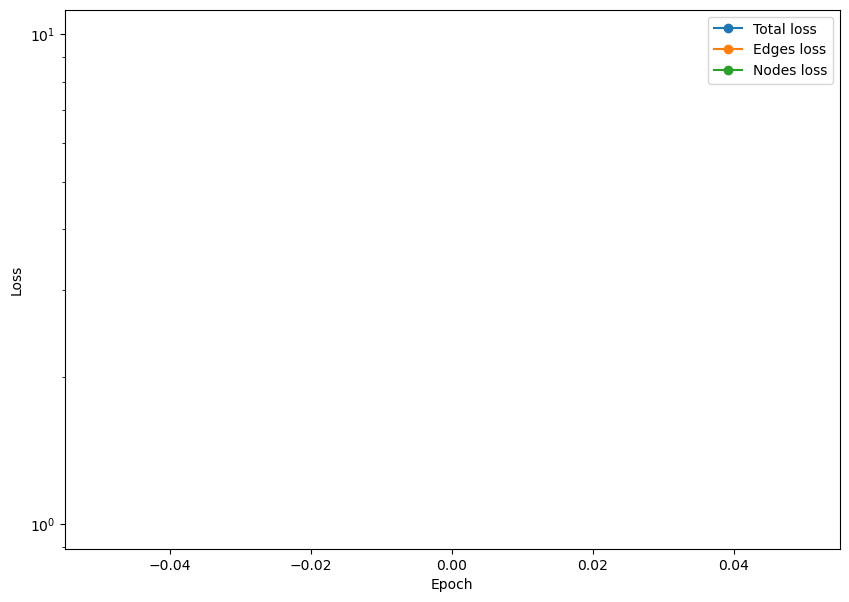

In [7]:
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (10, 7)})

plt.plot(losses, label="Total loss", marker="o")
plt.plot(losses_edges, label="Edges loss", marker="o")
plt.plot(losses_nodes, label="Nodes loss", marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.legend()
plt.show()

In [ ]:
# Evaluate the model on the test set

model.eval()

losses_testing_qcd = []

for graph in tqdm(loader_testing, desc="Testing QCD", leave=True):
    x = graph.x
    edges = graph.edge_index

    edges_loss = model.edges_loss(
        x,
        edges,
        negative_sampling(
            edges,
        ).to(device),
    )

    features_loss = model.features_loss(x, edges)
    loss = edges_loss + alpha*features_loss

    losses_testing_qcd.append(float(loss.detach()))

losses_testing_signal = []

for graph in tqdm(loader_signal, desc="Testing SVJ", leave=True):
    x = graph.x
    edges = graph.edge_index

    edges_loss = model.edges_loss(
        x,
        edges,
        negative_sampling(
            edges,
        ).to(device),
    )

    features_loss = model.features_loss(x, edges)
    loss = edges_loss + alpha*features_loss

    losses_testing_signal.append(float(loss.detach()))

In [ ]:
plt.hist(losses_testing_qcd, bins=50, histtype="step", label="QCD", density=True)
plt.hist(losses_testing_signal, bins=50, histtype="step", label="Signal", density=True)
plt.xlabel("Loss")
plt.ylabel("Density")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve

y_true = [0]*len(losses_testing_qcd) + [1]*len(losses_testing_signal)
y_score = losses_testing_qcd + losses_testing_signal

fpr, tpr, _ = roc_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.show()